# Student Grade Prediction model
- Research Question: É possível prever as notas de alunos a partir de dados socioeconômicos?
- Business Question: Quais segmentos de alunos devem ser endereçados com políticas de permanência que tenham como foco aumentar o rendimento acadêmico?

O estudo irá endereçar aspectos em 4 frentes: **características dos alunos; estrutura familiar; inclusão tecnológica e situação escolar**. O objetivo é abordar o potencial de políticas de inclusão e permanência no rendimento acadêmico de alunos com baixo status socioeconômico.

O estudo possui as seguintes etapas:
- **Análise exploratória de dados**: estatísticas descritivas e testes estatísticos simples como Test T-Student e Regressão Linear para identificar variáveis com correlação mais forte com a nota.
- **Aplicação de ML para predição**: identificação de quais variáveis tem maior poder de predição da nota.
- **Report de resultados analíticos por segmentação e geração de insights acionáveis de políticas públicas**: Análise de clusters dos alunos por desempenho acadêmico classificado em 'reprovação', 'público de risco', 'alunos na média', 'alunos de alto desempenho', tendo em vista traçar políticas de permanência e inclusão distintas para cada um deles.

In [1]:
# loading libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [2]:
df = pd.read_csv('student_grade_ses_dataset.csv', sep=',')  # Carregando o dataset de notas dos alunos
df.head()  # Exibindo as primeiras linhas do DataFrame

,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
0,STU101529,2024-2025,2025-03-06,16,Male,12,Government,Rural,3,0,...,4.0,No Scholarship,0,4,15.0,76.8,61.7,59.4,D,0
1,STU107546,2022-2023,2025-05-02,15,Male,10,Government,Urban,3,1,...,0.7,No Scholarship,0,3,20.9,74.5,49.2,60.2,C,0
2,STU103737,2024-2025,2025-03-21,14,Male,9,Government,Urban,2,0,...,2.9,No Scholarship,0,4,20.9,94.9,56.9,58.4,D,0
3,STU108172,2023-2024,2025-03-30,13,Male,8,Government,Rural,6,4,...,7.0,No Scholarship,0,1,6.5,63.6,49.3,57.0,D,0
4,STU110633,2023-2024,2025-05-06,11,Female,6,Private-Unaided,Rural,5,3,...,9.1,No Scholarship,0,5,13.9,86.0,79.3,88.7,B,0


Vamos começar por uma etapa de análise exploratória, fundamental para conhecer a distribuição dos dados e estabelecer testes de hipóteses

## Variáveis presentes no banco
O banco possui as seguintes variáveis:
- `student_id`: identificador único do aluno.
- `academic_year`: ano letivo.
- `survey_date`: data da coleta dos dados.
- `age`: idade do aluno.
- `gender`: gênero do aluno.
- `grade_level`: série escolar.
- `school_type`: tipo de escola.
- `residence_type`: área de residência, urbana ou rural.
- `family_size`: número de pessoas na família.
- `num_siblings`: número de irmãos.
- `single_parent_household`: indica se o aluno vive em família monoparental.
- `family_income_bracket`: faixa de renda familiar.
- `annual_family_income_inr`: renda familiar anual em rúpias indianas.
- `father_education_level`: nível de escolaridade do pai.
- `mother_education_level`: nível de escolaridade da mãe.
- `father_occupation`: ocupação do pai.
- `mother_occupation`: ocupação da mãe.
- `has_internet_access`: indica se há acesso à internet.
- `has_computer_or_laptop`: indica se há computador ou notebook em casa.
- `distance_to_school_km`: distância até a escola, em quilômetros.
- `scholarship_status`: situação da bolsa de estudos.
- `extra_tutoring`: indica se o aluno recebe aulas de reforço.
- `parental_involvement_score`: pontuação de envolvimento dos responsáveis.
- `study_hours_per_week`: horas de estudo por semana.
- `attendance_rate_pct`: percentual de frequência escolar.
- `previous_year_grade_pct`: nota percentual do ano anterior.
- `final_grade_pct`: nota percentual final.
- `grade_class`: classificação da nota final.
- `at_risk_flag`: indica se o aluno está em situação de risco acadêmico.

## Quais são as variáveis de interesse?
- `final_grade_pct`: uma variável contínua que indica a nota percentual final de 0 a 100.
- `at_risk_flag`: uma variável dummy que indica situação de risco acadêmico.

## Quais são as variáveis preditoras?
As variáveis preditoras serão agrupadas da seguinte forma:

### Características dos alunos
- `gender`: gênero do aluno.
- `age`: idade do aluno.

## Estrutura familiar
- `distance_to_school_km`: distância até a escola, em quilômetros.
- `residence_type`: área de residência, urbana ou rural.
- `family_size`: número de pessoas na família.
- `family_income_bracket`: faixa de renda familiar.
- `single_parent_household`: indica se o aluno vive em família monoparental.
- `father_education_level`: nível de escolaridade do pai.
- `mother_education_level`: nível de escolaridade da mãe.
- `father_occupation`: ocupação do pai.
- `mother_occupation`: ocupação da mãe.
- `parental_involvement_score`: pontuação de envolvimento dos responsáveis.

## Inclusão tecnológica
- `has_internet_access`: indica se há acesso à internet.
- `has_computer_or_laptop`: indica se há computador ou notebook em casa.

## Situação escolar
- `school_type`: tipo de escola.
- `scholarship_status`: situação da bolsa de estudos.
- `extra_tutoring`: indica se o aluno recebe aulas de reforço.
- `study_hours_per_week`: horas de estudo por semana.
- `attendance_rate_pct`: percentual de frequência escolar.

## Quais são as hipóteses em relação a cada grupo de variáveis preditoras?
- Características dos alunos: relação de causalidade fraca entre gênero, idade e rendimento acadêmico.
- Estrutura familiar: relaçao de causalidade forte entre famílias de baixa renda, em zona rural, longe da escola, e com baixo envolvimento parental nos estudos e baixa escolaridade dos pais.
- Inclusão tecnológica: relação de causalidade fraca.
- Situação Escolar: relação de causalidade forte e que supera o potencial explicativo da estrutura familiar, ou seja, alunos que recebem apoio acadêmico na forma de reforços, bolsas e têm acesso a escolas de melhor qualidade, têm melhor rendimento acadêmico mesmo em famílias de baixo padrão socioeconômico, o que reforça a necessidade de implementar essas políticas.


# Etapa 1: Criação de um dicionário de dados e Análise Exploratória de Dados
Vamos agrupar as variáveis de acordo com os grupos analíticos determinados e os tipos de dados para decidirmos as visualizações adequadas e modelos preditivos.

In [3]:
# criando as listas de grupos analíticos
grupos_analiticos = {
    "Características dos alunos": [
        "gender",
        "age"
    ],
    "Estrutura familiar": [
        "distance_to_school_km",
        "residence_type",
        "family_size",
        "family_income_bracket",
        "single_parent_household",
        "father_education_level",
        "mother_education_level",
        "father_occupation",
        "mother_occupation",
        "parental_involvement_score"
    ],
    "Inclusão tecnológica": [
        "has_internet_access",
        "has_computer_or_laptop"
    ],
    "Situação escolar": [
        "school_type",
        "scholarship_status",
        "extra_tutoring",
        "study_hours_per_week",
        "attendance_rate_pct"
    ]
}

print('Lista dos grupos analíticos com as variáveis correspondentes criada com sucesso!')
print(grupos_analiticos)

Lista dos grupos analíticos com as variáveis correspondentes criada com sucesso!
{'Características dos alunos': ['gender', 'age'], 'Estrutura familiar': ['distance_to_school_km', 'residence_type', 'family_size', 'family_income_bracket', 'single_parent_household', 'father_education_level', 'mother_education_level', 'father_occupation', 'mother_occupation', 'parental_involvement_score'], 'Inclusão tecnológica': ['has_internet_access', 'has_computer_or_laptop'], 'Situação escolar': ['school_type', 'scholarship_status', 'extra_tutoring', 'study_hours_per_week', 'attendance_rate_pct']}


In [4]:
# criando um dicionário de dados a partir dos grupos analíticos e do tipo de cada variável
#colocando o nome das oclunas numa lista
nomes_colunas = df.columns.tolist()

# Cria a lista onde iremos classificar as variáveis com o grupo analítico correspondente
linhas_metadados = []
for grupo_analitico, variaveis_grupo in grupos_analiticos.items():
    for var in variaveis_grupo:
        #Se a variável existe no df, obter o tipo de dado
        if var in df:
            tipo = str(df[var].dtype)
        else:
            tipo = 'Não encontrado no DATAFRAME'
        linhas_metadados.append({
            'variavel': var,
            'grupo_analitico': grupo_analitico,
            'tipo_dado': tipo
        })

df_dicionario = pd.DataFrame(linhas_metadados)
print(df_dicionario)

                      variavel             grupo_analitico tipo_dado
0                       gender  Características dos alunos       str
1                          age  Características dos alunos     int64
2        distance_to_school_km          Estrutura familiar   float64
3               residence_type          Estrutura familiar       str
4                  family_size          Estrutura familiar     int64
5        family_income_bracket          Estrutura familiar       str
6      single_parent_household          Estrutura familiar     int64
7       father_education_level          Estrutura familiar       str
8       mother_education_level          Estrutura familiar       str
9            father_occupation          Estrutura familiar       str
10           mother_occupation          Estrutura familiar       str
11  parental_involvement_score          Estrutura familiar     int64
12         has_internet_access        Inclusão tecnológica   float64
13      has_computer_or_laptop    

## Grupo 1: Características dos alunos
Esse grupo traz as variáveis de gênero e idade, as quais colocamos como hipótese uma baixa relação causal com o rendimento acadêmico. Segue o esquema utilizado:

In [5]:
# Colunas desejadas - as que correspondendo a 'Características dos alunos' no df_dicionario
filtro = df_dicionario["grupo_analitico"] == "Características dos alunos"
colunas_desejadas = df_dicionario.loc[filtro, "variavel"].tolist()
df_caracteristicas_dos_alunos = df.loc[:, colunas_desejadas]
print(df_caracteristicas_dos_alunos)

df_caracteristicas_dos_alunos.describe()

       gender  age
0        Male   16
1        Male   15
2        Male   14
3        Male   13
4      Female   11
...       ...  ...
12020    Male   14
12021  Female   12
12022    Male   15
12023    Male   11
12024  Female   12

[12025 rows x 2 columns]


,age
count,12025.000000
mean,13.986362
std,2.151717
min,10.000000
25%,12.000000
50%,14.000000
75%,16.000000
max,18.000000


In [ ]:
# [ Dicionário de Grupos Analíticos]
#               │
#               ▼ (Iteração por cada grupo utilizando o dicionário para organizar os 
#                 gráficos diretamente)
# [ Criação da Pasta 'graficos_distribuicao/' ]
#               │
#               ▼ (Cálculo de linhas com base em 2 colunas)
# [ plt.subplots(nrows, ncols=2) ]
#               │
#         ┌─────┴───detecção automática do tipo de cada variável─────────────────────┐
#         ▼                              ▼
#  [ Se Numérica ]                [ Se Categórica ]
#  • Histograma + KDE             • Gráfico de barras
#                                 • Cálculo das percentagens (%)
#                                 • Inserção do rótulo dentro da barra
#               │
#               ▼
#[ Ocultar eixos vazios na grade ]
#               │
#               ▼
#[ fig.savefig('graficos_distribuicao/grupo_X.png') ]

In [6]:
# Configuração de estilo visual dos gráficos
sns.set_theme(style="whitegrid", palette="deep")

✅ Gráfico salvo com sucesso como: distribuicao_idades_genero.png


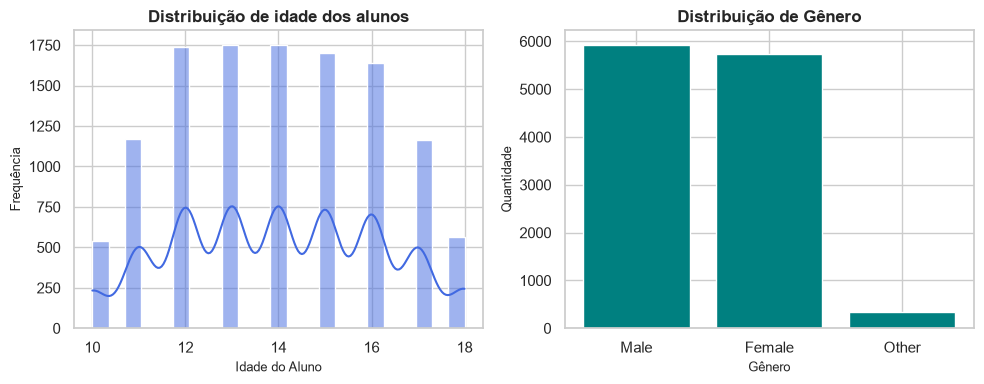

In [7]:
# Como criar uma grid de 1 linha e 2 colunas
# fig = a imagem
# ax1 e ax2 são os quadrantes
fig, (ax1, ax2) = plt.subplots(
    nrows = 1, 
    ncols = 2, 
    figsize = (10,4))
#agora vamos fazer o gráfico da esquerda, um histograma com KDE das idades
sns.histplot(
    data=df,
    x = 'age',
    kde=True,
    ax=ax1,
    color="royalblue")
#colocação o título desse gráfico
ax1.set_title(
    "Distribuição de idade dos alunos",
    fontsize = 12,
    fontweight = "bold")
# editando o título das labels
ax1.set_ylabel("Frequência", fontsize = 9)
ax1.set_xlabel("Idade do Aluno", fontsize = 9)
# agora vamos fazer o gráfico da direita, um gráfico de barras do gênero dos alunos com o % dentro das barras
#contando quantos generos tem
contagens = df['gender'].value_counts()
#Desenhando as barras no eixo ax2
barras = ax2.bar(contagens.index, contagens.values, color = "teal")
#colocando títulos
ax2.set_title("Distribuição de Gênero", fontsize=12, fontweight="bold")
ax2.set_ylabel("Quantidade", fontsize = 9)
ax2.set_xlabel("Gênero", fontsize = 9)

#salvando
plt.tight_layout()
nome_arquivo = "viz/distribuicao_idades_genero.png"
fig.savefig(nome_arquivo, dpi=300, bbox_inches="tight")
print(f"✅ Gráfico salvo com sucesso como: {nome_arquivo}")

# Garante que títulos e rótulos não colidam nem fiquem colados nas bordas

plt.show()

In [8]:
# Executando o teste T-Student para ver se as notas são diferentes entre meninas e meninos
# isolando as notas das mulheres e dos homens
notas_mulheres = df.loc[
    df["gender"] == "Female", "final_grade_pct"].dropna()

notas_homens = df.loc[
    df["gender"] == "Male", "final_grade_pct"].dropna()

df.head()
print(notas_mulheres)
print(notas_homens)

4        88.7
6        42.1
8        63.1
9        81.3
13       70.4
         ... 
12014    78.2
12018    68.6
12019    79.0
12021    63.1
12024    74.6
Name: final_grade_pct, Length: 5745, dtype: float64
0        59.4
1        60.2
2        58.4
3        57.0
5        88.3
         ... 
12016    67.2
12017    65.5
12020    77.2
12022    49.9
12023    56.5
Name: final_grade_pct, Length: 5931, dtype: float64


### Teste T-Student para avaliar se há diferenças estatisticamente significantes entre meninos e meninas

In [9]:
# Médias e desvio padrão de cada grupo
media_mulheres = notas_mulheres.mean()
media_homens = notas_homens.mean()
sd_mulheres = notas_mulheres.std()
sd_homens = notas_homens.std()
print('RESUMO DAS NOTAS')
print(f"Total de alunas: {len(notas_mulheres)} | Média: {media_mulheres:.2f} (± {sd_mulheres:.2f})")
print(f"Total de alunos: {len(notas_homens)} | Média: {media_homens:.2f} (± {sd_homens:.2f})")
print(f"Diferença entre as médias: {abs(media_mulheres - media_homens):.2f} pontos")
print("\n" + "="*50 + "\n")

RESUMO DAS NOTAS
Total de alunas: 5745 | Média: 66.94 (± 11.69)
Total de alunos: 5931 | Média: 66.99 (± 11.68)
Diferença entre as médias: 0.05 pontos




In [10]:
# Aplicando o test-t de student
estatistica_t, p_valor = stats.ttest_ind(
    notas_mulheres, notas_homens,
    equal_var=False
)

print("--- RESULTADO DO TESTE T DE STUDENT ---")
print(f"Estatística t: {estatistica_t:.4f}")
print(f"p-valor:       {p_valor:.4f}")
print("-" * 50)

# Interpretação com a regra clássica de significância (p < 0.05)
if p_valor < 0.05: # type: ignore
    print("✅ Conclusão: Há uma diferença ESTATISTICAMENTE SIGNIFICATIVA entre as notas.")
    if media_mulheres > media_homens:
        print("As alunas obtiveram uma média significativamente maior.")
    else:
        print("Os alunos obtiveram uma média significativamente maior.")
else:
    print("❌ Conclusão: NÃO há diferença estatisticamente significativa entre as notas.")
    print("A diferença observada entre as médias pode ter ocorrido por pura variação amostral.")

print("\n" + "="*50 + "\n")

--- RESULTADO DO TESTE T DE STUDENT ---
Estatística t: -0.2341
p-valor:       0.8149
--------------------------------------------------
❌ Conclusão: NÃO há diferença estatisticamente significativa entre as notas.
A diferença observada entre as médias pode ter ocorrido por pura variação amostral.




✅ Gráfico salvo com sucesso como: tstudent_notas_genero.png


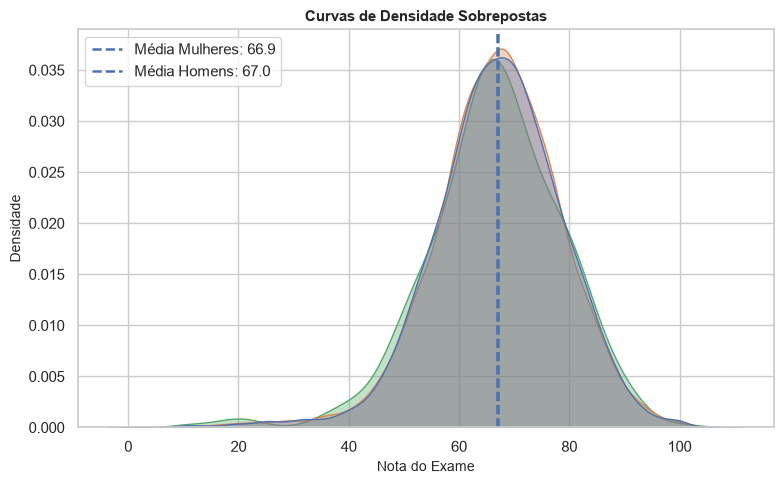

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

    # --- CURVAS DE DENSIDADE KDE ---
sns.kdeplot(
        data=df,
        x="final_grade_pct",
        hue="gender",
        common_norm=False,
        fill=True,
        alpha=0.35,
        ax=ax
    )

    # Adiciona linhas pontilhadas marcando a média de cada grupo
ax.axvline(
        media_mulheres,
        linestyle="--",
        linewidth=1.8,
        label=f"Média Mulheres: {media_mulheres:.1f}"
    )
ax.axvline(
        media_homens,
        linestyle="--",
        linewidth=1.8,
        label=f"Média Homens: {media_homens:.1f}"
    )

ax.set_title("Curvas de Densidade Sobrepostas", fontsize=11, fontweight="bold")
ax.set_xlabel("Nota do Exame", fontsize=10)
ax.set_ylabel("Densidade", fontsize=10)
ax.legend(loc="upper left")

# ----------------------------------------------------------
# ETAPA 6: AJUSTE FINAL E SALVAMENTO EM PNG
# ----------------------------------------------------------
plt.tight_layout()
#nome_arquivo = "tstudent_notas_genero.png"
#fig.savefig(nome_arquivo, dpi=300, bbox_inches="tight")
#print(f"✅ Gráfico salvo com sucesso como: {nome_arquivo}")



### Regressão linear para avaliar a relação entre final_grade_pct e age
- Direção: Conforme a idade aumenta, a nota tende a subir (inclinação positiva) ou a descer (inclinação negativa)?
- Impacto: Para cada ano a mais de idade, quantos pontos a nota muda em média (o coeficiente angular $a$)?Força do ajuste: 
- Qual a percentagem da variação das notas que a idade consegue explicar ($R^2$ / $R$-quadrado)?

A correlação 'r' varia entre -1 e +1:
- Próximo de +1: Forte relação positiva (uma sobe, a outra sobe)
- Próximo de  0: Nenhuma relação linear aparente
- Próximo de -1: Forte relação negativa (uma sobe, a outra desce)

In [28]:
correlacao_idade_nota = df["age"].corr(df["final_grade_pct"])
print(f"Coeficiente de Correlação de Pearson (r): {correlacao_idade_nota:.3f}")

if abs(correlacao_idade_nota) > 0.7:
    forca = "forte"
elif abs(correlacao_idade_nota) > 0.3:
    forca = "moderada"
else:
    forca = "fraca ou quase nula"

print(f"Interpretação: Relação linear {forca}.")
print("\n" + "="*50 + "\n")

Coeficiente de Correlação de Pearson (r): 0.002
Interpretação: Relação linear fraca ou quase nula.




In [31]:
# X: Variável de entrada/preditora (precisa de estar no formato DataFrame com [[ ]])
# y: Variável de saída/alvo (a nota que queremos prever)
X = df[["age"]]
y = df["final_grade_pct"]

# 1. Instanciamos o modelo linear
modelo_idade_nota = LinearRegression()

# 2. Treinamos o modelo para encontrar a reta ideal (Mínimos Quadrados)
modelo_idade_nota.fit(X, y)

# 3. Geramos as previsões ao longo dos dados
previsoes = modelo_idade_nota.predict(X)

# 4. Extraímos os parâmetros fundamentais da reta: y = ax + b
coeficiente_angular = modelo_idade_nota.coef_[0]   # 'a' (inclinação)
intercepto = modelo_idade_nota.intercept_          # 'b' (onde a reta cruza o eixo Y)
r2 = r2_score(y, previsoes)             # R² (percentagem de variância explicada)

print("--- 2. RESULTADOS DA REGRESSÃO LINEAR ---")
print(f"Equação da Reta:      Nota = ({coeficiente_angular:.2f} * Idade) + ({intercepto:.2f})")
print(f"Coeficiente Angular:  {coeficiente_angular:.2f} pontos por cada ano de idade")
print(f"Intercepto Base:      {intercepto:.2f}")
print(f"Coeficiente R²:       {r2:.3f} (explica {r2 * 100:.1f}% da variação da nota)")
print("\n" + "="*50 + "\n")

--- 2. RESULTADOS DA REGRESSÃO LINEAR ---
Equação da Reta:      Nota = (0.01 * Idade) + (66.82)
Coeficiente Angular:  0.01 pontos por cada ano de idade
Intercepto Base:      66.82
Coeficiente R²:       0.000 (explica 0.0% da variação da nota)




✅ Gráfico salvo com sucesso no arquivo: regressao_idade_vs_nota.png


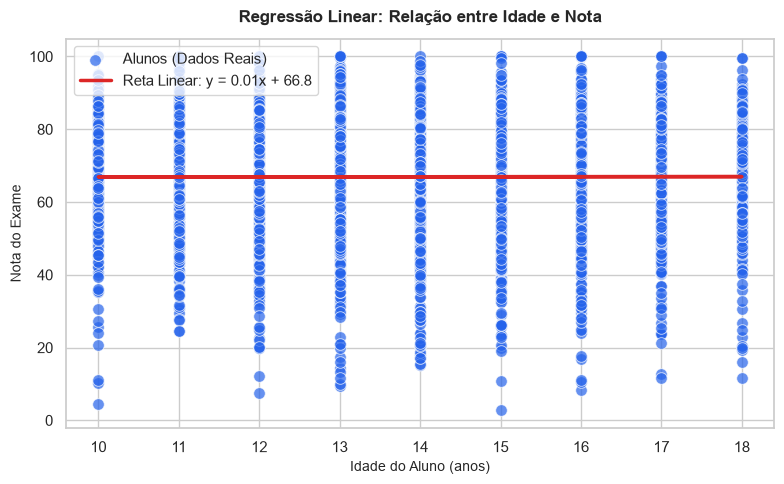

In [ ]:
# ----------------------------------------------------------
# ETAPA 5: VISUALIZAÇÃO GRÁFICA COM DISPERSÃO E RETA
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))

# 1. Desenhamos os pontos reais dos alunos (Dispersão)
sns.scatterplot(
    data=df,
    x="age",
    y="final_grade_pct",
    color="#2563eb",
    s=70,
    alpha=0.7,
    label="Alunos (Dados Reais)",
    ax=ax
)

# 2. Desenhamos a reta da regressão linear calculada pelo modelo
ax.plot(
    df["age"],
    previsoes,
    color="#dc2626",
    linewidth=2.5,
    label=f"Reta Linear: y = {coeficiente_angular:.2f}x + {intercepto:.1f}"
)

# Configurações de títulos e eixos
ax.set_title("Regressão Linear: Relação entre Idade e Nota", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Idade do Aluno (anos)", fontsize=10)
ax.set_ylabel("Nota do Exame", fontsize=10)
ax.legend(loc="upper left")

# Ajuste de margens
plt.tight_layout()

# ----------------------------------------------------------
# ETAPA 6: SALVAMENTO DO GRÁFICO EM PNG
# ----------------------------------------------------------
#nome_arquivo = "regressao_idade_vs_nota.png"
#fig.savefig(nome_arquivo, dpi=300, bbox_inches="tight")
#print(f"✅ Gráfico salvo com sucesso no arquivo: {nome_arquivo}")

# Exibe o gráfico no ecrã
plt.show()

Conclusão: Não há diferenças estatisticamente significantes entre os gêneros e idades em relação às notas. Deste modo, características intrínsecas dos alunos não explicam, por si só, o desempenho acadêmico.

## Grupo 2: Estrutura familiar
Avaliamos se a escolaridade e ocupação dos pais, envolvimento parental nos estudos, cacterísticas das residências e renda explicam as notas finais dos alunos (variável final_grade_pct)

In [39]:
df_dicionario[df_dicionario["grupo_analitico"] == "Estrutura familiar"].sort_values(by='tipo_dado')

,variavel,grupo_analitico,tipo_dado
2,distance_to_school_km,Estrutura familiar,float64
4,family_size,Estrutura familiar,int64
6,single_parent_household,Estrutura familiar,int64
11,parental_involvement_score,Estrutura familiar,int64
3,residence_type,Estrutura familiar,str
5,family_income_bracket,Estrutura familiar,str
7,father_education_level,Estrutura familiar,str
8,mother_education_level,Estrutura familiar,str
9,father_occupation,Estrutura familiar,str
10,mother_occupation,Estrutura familiar,str


In [48]:
# Colunas desejadas - as que correspondendo a 'Estrutura Familiar' no df_dicionario
filtro = df_dicionario["grupo_analitico"] == "Estrutura familiar"
colunas_desejadas = df_dicionario.loc[filtro, "variavel"].tolist()
df_estrutura_familiar = df.loc[:, colunas_desejadas]

In [46]:
df_estrutura_familiar.value_counts()

distance_to_school_km  residence_type  family_size  family_income_bracket  single_parent_household  father_education_level  mother_education_level  father_occupation         mother_occupation         parental_involvement_score
1.1                    Urban           5            Low                    0                        Higher Secondary        Primary                 Unemployed                Unemployed                3                             2
2.0                    Urban           4            Lower-Middle           0                        No Formal Education     No Formal Education     Unskilled Labor           Homemaker                 5                             2
0.8                    Semi-Urban      6            Low                    0                        Primary                 Higher Secondary        Skilled Labor / Trade     Professional              4                             2
10.9                   Rural           2            Middle                 0 

In [47]:
df_estrutura_familiar.describe()

,distance_to_school_km,family_size,single_parent_household,parental_involvement_score
count,11784.000000,12025.000000,12025.000000,12025.000000
mean,3.883961,4.597588,0.140042,3.246570
std,3.581107,1.396749,0.347045,0.941216
min,0.200000,2.000000,0.000000,1.000000
25%,1.500000,4.000000,0.000000,3.000000
50%,2.800000,5.000000,0.000000,3.000000
75%,5.100000,6.000000,0.000000,4.000000
max,31.200000,10.000000,1.000000,5.000000


- Variáveis numéricas:
    - family_size
    - distance_to_school_km
    Correlação de Pearson e Regressão Linear

- Variáveis dummy
    - single_parent_household - Teste T de Student

- Variáveis categóricas
    - residence_type - 3 categorias (teste anova)
    - education level - 5 categorias ordinais
    - ocupation - 5 categorias (teste anova)
    - parental_envolvement_score - 5 categorias ordenadas (teste anova)

    

### Variáveis Numéricas: family_size e distance_to_school_km

In [ ]:
# Distribuição da variável family_size
print("--- DISTRIBUIÇÃO DA VARIÁVEL 'family_size' ---")
print(df['family_size'].value_counts().sort_index())
print("\n" + "=" * 65 + "\n")

--- DISTRIBUIÇÃO DA VARIÁVEL 'family_size' ---
family_size
2      837
3     1780
4     3124
5     3247
6     1988
7      821
8      191
9       32
10       5
Name: count, dtype: int64




In [ ]:
# Correlação de Pearson entre tamanho da família e nota
# Isolando as variáveis e removendo valores na
dados_family_size = df[["family_size", "final_grade_pct"]].dropna()
x = dados_family_size["family_size"]
y = dados_family_size["final_grade_pct"]

# Calculando a Correlação Linear de Pearson
r_pearson, p_pearson = stats.pearsonr(x, y)

# 2. Correlação Monotônica de Spearman (avalia postos/ranks)
rho_spearman, p_spearman = stats.spearmanr(x, y)

print("--- RESULTADOS DE CORRELAÇÃO ---")
print(f"1. Correlação de Pearson (r):   {r_pearson:.4f} (p-valor: {p_pearson:.4f})")
print(f"2. Correlação de Spearman (rho): {rho_spearman:.4f} (p-valor: {p_spearman:.4f})")
print("-" * 65)

# Interpretação prática do coeficiente de Pearson
if p_pearson < 0.05:
    print(" Conclusão: A correlação é ESTATISTICAMENTE SIGNIFICATIVA (p < 0.05).")
    if r_pearson > 0:
        print("  Tendência positiva: famílias maiores associadas a notas maiores.")
    else:
        print("  Tendência negativa: famílias maiores associadas a notas ligeiramente menores.")
else:
    print("❌ Conclusão: NÃO há evidência suficiente de correlação linear (p >= 0.05).")

print("\n" + "=" * 65 + "\n")

--- RESULTADOS DE CORRELAÇÃO ---
1. Correlação de Pearson (r):   -0.0522 (p-valor: 0.0000)
2. Correlação de Spearman (rho): -0.0544 (p-valor: 0.0000)
-----------------------------------------------------------------
 Conclusão: A correlação é ESTATISTICAMENTE SIGNIFICATIVA (p < 0.05).
  Tendência negativa: famílias maiores associadas a notas ligeiramente menores.




In [54]:
# Modelo de Regressão Linear
# X precisa ter formato de matriz (2 dimensões: linhas e colunas)
X_matriz = dados_family_size[["family_size"]]

modelo = LinearRegression()
modelo.fit(X_matriz, y)

inclinacao = modelo.coef_[0]
intercepto = modelo.intercept_
r2 = modelo.score(X_matriz, y)

print("--- MODELO DE REGRESSÃO LINEAR ---")
print(f"Equação: Nota = ({inclinacao:.2f} * family_size) + {intercepto:.2f}")
print(f"Impacto por membro: cada pessoa a mais na família altera a nota em {inclinacao:.2f} pontos.")
print(f"R² (Coeficiente de Determinação): {r2:.4f} ({r2 * 100:.2f}% da variação explicada)")
print("\n" + "=" * 65 + "\n")

--- MODELO DE REGRESSÃO LINEAR ---
Equação: Nota = (-0.44 * family_size) + 68.96
Impacto por membro: cada pessoa a mais na família altera a nota em -0.44 pontos.
R² (Coeficiente de Determinação): 0.0027 (0.27% da variação explicada)




 Gráfico salvo com sucesso como 'correlacao_family_size.png'!


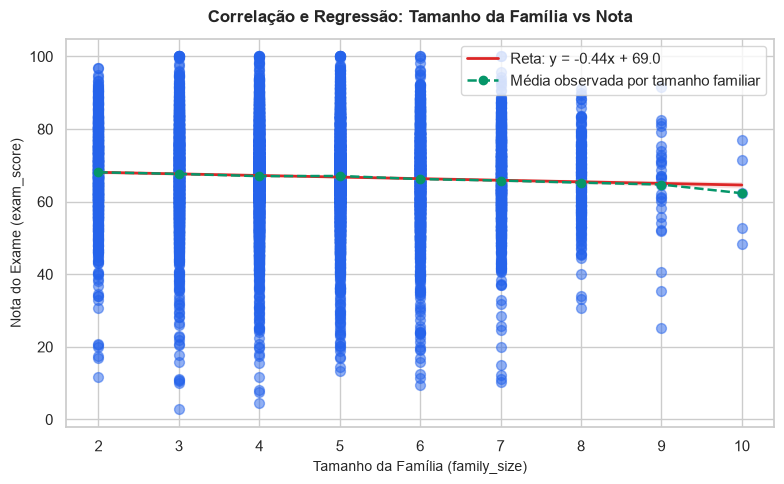

In [ ]:
# PASSO 5: VISUALIZAÇÃO GRÁFICA (DISPERSÃO + RETA + MÉDIAS)
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))

# 1. Gráfico de dispersão com pequena transparência para lidar com sobreposição
sns.regplot(
    data=df,
    x="family_size",
    y="final_grade_pct",
    color="#2563eb",
    scatter_kws={"alpha": 0.5, "s": 50},
    line_kws={"color": "#dc2626", "linewidth": 2, "label": f"Reta: y = {inclinacao:.2f}x + {intercepto:.1f}"},
    ax=ax
)

# 2. Marcador da média real para cada valor de family_size (2 a 10)
medias_por_tamanho = df.groupby("family_size")["final_grade_pct"].mean()
ax.plot(
    medias_por_tamanho.index,
    medias_por_tamanho.values,
    color="#059669",
    marker="o",
    linewidth=1.8,
    linestyle="--",
    label="Média observada por tamanho familiar"
)

ax.set_title("Correlação e Regressão: Tamanho da Família vs Nota", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Tamanho da Família (family_size)", fontsize=10)
ax.set_ylabel("Nota do Exame (exam_score)", fontsize=10)
ax.set_xticks(range(2, 11))
ax.legend(loc="upper right")

plt.tight_layout()
#nome_arquivo = "correlacao_family_size.png"
#fig.savefig(nome_arquivo, dpi=300, bbox_inches="tight")
#print(f" Gráfico salvo com sucesso como '{nome_arquivo}'!")

plt.show()

In [61]:
#Distribuição da distância
distancia = df["distance_to_school_km"].dropna()

media_distancia = distancia.mean()
mediana_distancia = distancia.median()

print("--- RESUMO DA VARIÁVEL 'distance_to_school_km' ---")
print(f"Total de registros:  {len(distancia)}")
print(f"Distância mínima:    {distancia.min():.1f} km")
print(f"Distância média:     {media_distancia:.2f} km")
print(f"Distância mediana:   {mediana_distancia:.2f} km")
print(f"Distância máxima:    {distancia.max():.1f} km")
print("=" * 60)

--- RESUMO DA VARIÁVEL 'distance_to_school_km' ---
Total de registros:  11784
Distância mínima:    0.2 km
Distância média:     3.88 km
Distância mediana:   2.80 km
Distância máxima:    31.2 km



✅ Histograma salvo com sucesso no arquivo: 'histograma_distancia.png'


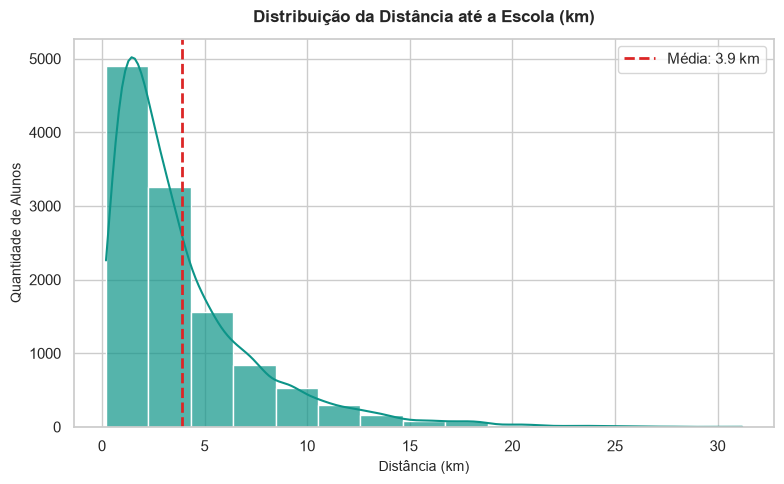

In [ ]:
# Cria a figura e a área de desenho (eixo)
fig, ax = plt.subplots(figsize=(8, 5))

# Desenha o histograma com curva suave de densidade (kde=True)
sns.histplot(
    data=distancia,
    kde=True,                  # Adiciona a linha de densidade suave
    bins=15,                   # Divide os dados em 15 faixas de distância
    color="#0d9488",           # Cor verde-petróleo elegante
    edgecolor="white",         # Borda branca entre as barras para separar bem
    alpha=0.7,                 # Leve transparência nas barras
    ax=ax
)

# Adiciona uma linha vertical vermelha tracejada indicando a média
ax.axvline(
    media_distancia,
    color="#dc2626",
    linestyle="--",
    linewidth=2,
    label=f"Média: {media_distancia:.1f} km"
)

# ----------------------------------------------------------
# PASSO 5: TÍTULOS, RÓTULOS E LEGENDA
# ----------------------------------------------------------
ax.set_title("Distribuição da Distância até a Escola (km)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Distância (km)", fontsize=10)
ax.set_ylabel("Quantidade de Alunos", fontsize=10)
ax.legend(loc="upper right", frameon=True)

# ----------------------------------------------------------
# PASSO 6: AJUSTE DO ESPAÇAMENTO E GRAVAÇÃO EM PNG
# ----------------------------------------------------------
plt.tight_layout()

#nome_arquivo = "histograma_distancia.png"
#fig.savefig(nome_arquivo, dpi=300, bbox_inches="tight")
#print(f"\n✅ Histograma salvo com sucesso no arquivo: '{nome_arquivo}'")

# ----------------------------------------------------------
# PASSO 7: EXIBIÇÃO NO ECRÃ
# ----------------------------------------------------------
plt.show()

In [66]:
# Correlação de pearson entre distância e nota
# Selecionamos apenas as duas colunas e removemos valores nulos
dados_validos = df[["distance_to_school_km", "final_grade_pct"]].dropna()

x = dados_validos["distance_to_school_km"]
y = dados_validos["final_grade_pct"]

# 1. Correlação Linear de Pearson (mede a força de uma linha reta entre as variáveis)
r_pearson, p_pearson = stats.pearsonr(x, y)

# 2. Correlação Monotônica de Spearman (avalia postos, robusta a valores discrepantes)
rho_spearman, p_spearman = stats.spearmanr(x, y)

print("--- 1. RESULTADOS DE CORRELAÇÃO ---")
print(f"• Correlação de Pearson (r):   {r_pearson:+.4f} | p-valor: {p_pearson:.4f}")
print(f"• Correlação de Spearman (rho): {rho_spearman:+.4f} | p-valor: {p_spearman:.4f}")
print("-" * 65)

# Interpretação prática do p-valor e do sinal da correlação
if p_pearson < 0.05:
    print(" Conclusão: A correlação é ESTATISTICAMENTE SIGNIFICATIVA (p < 0.05).")
    if r_pearson < 0:
        print("  Tendência negativa: quanto MAIOR a distância até a escola, MENOR tende a ser a nota final.")
    else:
        print("  Tendência positiva: quanto MAIOR a distância até a escola, MAIOR tende a ser a nota final.")
else:
    print("❌ Conclusão: NÃO há evidência estatística de correlação linear (p >= 0.05).")

print("\n" + "=" * 65 + "\n")

--- 1. RESULTADOS DE CORRELAÇÃO ---
• Correlação de Pearson (r):   -0.0248 | p-valor: 0.0072
• Correlação de Spearman (rho): -0.0287 | p-valor: 0.0018
-----------------------------------------------------------------
 Conclusão: A correlação é ESTATISTICAMENTE SIGNIFICATIVA (p < 0.05).
  Tendência negativa: quanto MAIOR a distância até a escola, MENOR tende a ser a nota final.




--- 2. RESULTADOS DA REGRESSÃO LINEAR ---
• Equação da Reta: final_grade_pct = (-0.08 * distance_to_school_km) + 67.25
• Inclinação (a):  -0.08% por quilómetro adicional.
• Intercepto (b):  67.25% (nota média estimada para quem mora colado à escola, km=0).
• Coeficiente R²:  0.0006 (a distância sozinha explica 0.06% da variação da nota final).


 Gráfico comparativo gravado com sucesso no arquivo: 'regressao_distancia_vs_nota.png'


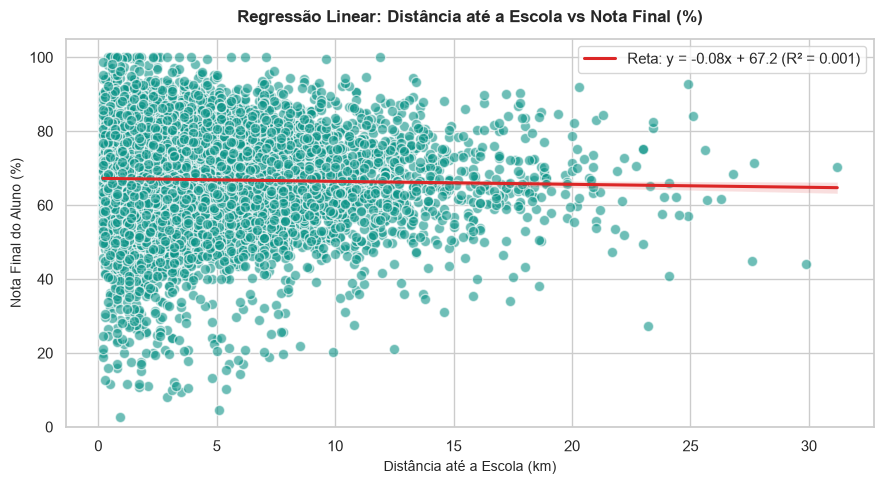

In [ ]:
# PASSO 5: MODELAGEM COM REGRESSÃO LINEAR SIMPLES
# ----------------------------------------------------------
# O Scikit-Learn exige que a variável explicativa X tenha 2 dimensões: [[coluna]]
X_matriz = dados_validos[["distance_to_school_km"]]

modelo_linear = LinearRegression()
modelo_linear.fit(X_matriz, y)

inclinacao = modelo_linear.coef_[0]   # Coeficiente angular (a)
intercepto = modelo_linear.intercept_ # Ponto de corte do eixo Y (b)
r2 = modelo_linear.score(X_matriz, y) # Coeficiente de determinação (R²)

print("--- 2. RESULTADOS DA REGRESSÃO LINEAR ---")
print(f"• Equação da Reta: final_grade_pct = ({inclinacao:.2f} * distance_to_school_km) + {intercepto:.2f}")
print(f"• Inclinação (a):  {inclinacao:+.2f}% por quilómetro adicional.")
print(f"• Intercepto (b):  {intercepto:.2f}% (nota média estimada para quem mora colado à escola, km=0).")
print(f"• Coeficiente R²:  {r2:.4f} (a distância sozinha explica {r2 * 100:.2f}% da variação da nota final).")
print("\n" + "=" * 65 + "\n")

# ----------------------------------------------------------
# PASSO 6: VISUALIZAÇÃO GRÁFICA E SALVAMENTO EM PNG
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))

# Desenhamos o gráfico de dispersão com a reta de regressão traçada
sns.regplot(
    data=dados_validos,
    x="distance_to_school_km",
    y="final_grade_pct",
    color="#0d9488",  # Verde-petróleo para os pontos
    scatter_kws={"alpha": 0.6, "s": 55, "edgecolors": "white"},
    line_kws={
        "color": "#dc2626", # Vermelho para destacar a reta
        "linewidth": 2.2,
        "label": f"Reta: y = {inclinacao:.2f}x + {intercepto:.1f} (R² = {r2:.3f})"
    },
    ax=ax
)

# Configurações de títulos e eixos
ax.set_title("Regressão Linear: Distância até a Escola vs Nota Final (%)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Distância até a Escola (km)", fontsize=10)
ax.set_ylabel("Nota Final do Aluno (%)", fontsize=10)
ax.set_ylim(0, 105) # Escala percentual com folga
ax.legend(loc="upper right", frameon=True)

# Ajuste de layout e gravação do arquivo
#plt.tight_layout()
#nome_arquivo = "regressao_distancia_vs_nota.png"
#fig.savefig(nome_arquivo, dpi=300, bbox_inches="tight")
#print(f" Gráfico comparativo gravado com sucesso no arquivo: '{nome_arquivo}'")

# Exibição da janela visual
plt.show()

### Variável Dummy: single_parent_household

In [71]:
# Padronização dos dois grupos
dados_validos = df[["single_parent_household", "final_grade_pct"]].dropna().copy()

# Padronizamos para garantir rótulos claros mesmo se os dados vierem como texto ou números
def rotular_grupo(valor):
    if str(valor).strip().lower() in ["1", "1.0", "sim", "yes", "true"]:
        return "Monoparental (Sim)"
    return "Biparental (Não)"

dados_validos["grupo_lar"] = dados_validos["single_parent_household"].apply(rotular_grupo)

print(dados_validos)

# Separamos as notas dos dois grupos em séries independentes
notas_biparental = dados_validos.loc[dados_validos["grupo_lar"] == "Biparental (Não)", "final_grade_pct"]
notas_monoparental = dados_validos.loc[dados_validos["grupo_lar"] == "Monoparental (Sim)", "final_grade_pct"]

       single_parent_household  final_grade_pct           grupo_lar
0                            1             59.4  Monoparental (Sim)
1                            0             60.2    Biparental (Não)
2                            0             58.4    Biparental (Não)
3                            0             57.0    Biparental (Não)
4                            1             88.7  Monoparental (Sim)
...                        ...              ...                 ...
12020                        0             77.2    Biparental (Não)
12021                        0             63.1    Biparental (Não)
12022                        0             49.9    Biparental (Não)
12023                        0             56.5    Biparental (Não)
12024                        1             74.6  Monoparental (Sim)

[12025 rows x 3 columns]


In [72]:
# PASSO 4: CÁLCULOS ESTATÍSTICOS DESCRITIVOS
# ----------------------------------------------------------
media_bi = notas_biparental.mean()
media_mono = notas_monoparental.mean()
desvio_bi = notas_biparental.std()
desvio_mono = notas_monoparental.std()
diferenca_medias = media_bi - media_mono

print("=" * 70)
print("ESTATÍSTICA DESCRITIVA: TIPO DE LAR VS NOTA FINAL")
print("=" * 70)
print(f"Grupo Biparental (Não):   Média = {media_bi:.2f}% (Desvio = {desvio_bi:.2f}, n = {len(notas_biparental)})")
print(f"Grupo Monoparental (Sim): Média = {media_mono:.2f}% (Desvio = {desvio_mono:.2f}, n = {len(notas_monoparental)})")
print(f"Diferença observada:      {diferenca_medias:+.2f} pontos percentuais")
print("-" * 70)

ESTATÍSTICA DESCRITIVA: TIPO DE LAR VS NOTA FINAL
Grupo Biparental (Não):   Média = 67.06% (Desvio = 11.75, n = 10341)
Grupo Monoparental (Sim): Média = 66.24% (Desvio = 11.37, n = 1684)
Diferença observada:      +0.82 pontos percentuais
----------------------------------------------------------------------


In [73]:
# PASSO 5: APLICAÇÃO DO TESTE T DE STUDENT (CORREÇÃO DE WELCH)
# ----------------------------------------------------------
# equal_var=False aplica o Teste t de Welch, ideal para amostras de tamanhos diferentes
t_stat, p_valor = stats.ttest_ind(notas_biparental, notas_monoparental, equal_var=False)

print("RESULTADO DO TESTE T DE STUDENT (WELCH):")
print(f"• Estatística t calculada: {t_stat:.4f}")
print(f"• p-valor obtido:          {p_valor:.4f}")
print("-" * 70)

# Interpretação didática da significância estatística
if p_valor < 0.05:
    print("✅ CONCLUSÃO: A diferença entre as notas é ESTATISTICAMENTE SIGNIFICATIVA (p < 0.05).")
    print(f"   Os alunos de lares biparentais apresentam nota média {abs(diferenca_medias):.2f}% superior")
    print("   de forma estatisticamente consistente nesta amostra.")
else:
    print("❌ CONCLUSÃO: NÃO há diferença estatisticamente significativa entre os grupos (p >= 0.05).")
    print("   A diferença observada nas médias pode ser fruto exclusivo de oscilações normais da amostra.")

print("=" * 70 + "\n")

RESULTADO DO TESTE T DE STUDENT (WELCH):
• Estatística t calculada: 2.7474
• p-valor obtido:          0.0061
----------------------------------------------------------------------
✅ CONCLUSÃO: A diferença entre as notas é ESTATISTICAMENTE SIGNIFICATIVA (p < 0.05).
   Os alunos de lares biparentais apresentam nota média 0.82% superior
   de forma estatisticamente consistente nesta amostra.



✅ Gráfico KDE salvo com sucesso no arquivo: 'kde_monoparental.png'


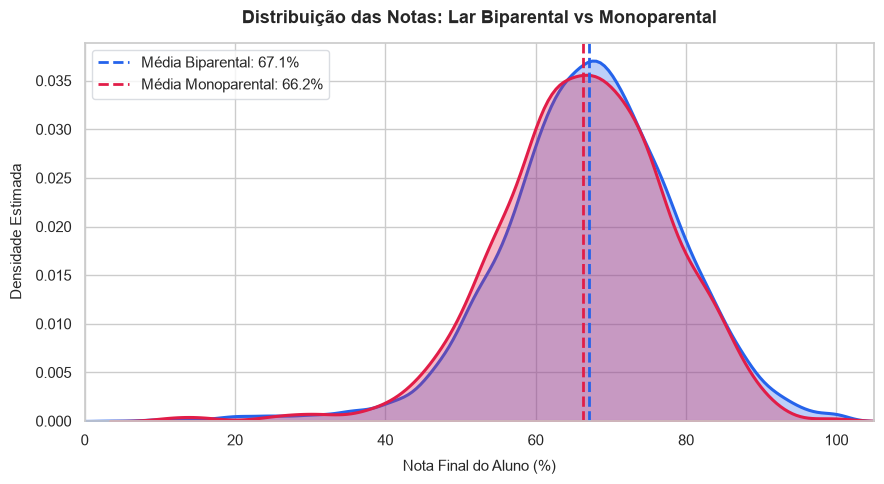

In [ ]:
# PASSO 5: CONSTRUÇÃO EXCLUSIVA DO GRÁFICO KDE SOBREPOSTO
# ----------------------------------------------------------
# Criamos uma única figura ampla e limpa (sem boxplot)
fig, ax = plt.subplots(figsize=(9, 5))

# Dicionário de cores com alto contraste
paleta_cores = {
    "Biparental (Não)": "#2563eb",   # Azul royal marcante
    "Monoparental (Sim)": "#e11d48"  # Rosa/coral elegante
}

# Desenho das curvas de densidade suaves
sns.kdeplot(
    data=dados_validos,
    x="final_grade_pct",
    hue="grupo_lar",
    palette=paleta_cores,
    common_norm=False,  # Normaliza cada curva de forma independente
    fill=True,          # Preenche a área sob as curvas
    alpha=0.30,         # Nível de transparência para sobreposição suave
    linewidth=2.2,      # Espessura destacada da linha contínua
    ax=ax
)

# Inserção das linhas verticais tracejadas marcando as médias
ax.axvline(
    media_bi,
    color=paleta_cores["Biparental (Não)"],
    linestyle="--",
    linewidth=2.0,
    label=f"Média Biparental: {media_bi:.1f}%"
)

ax.axvline(
    media_mono,
    color=paleta_cores["Monoparental (Sim)"],
    linestyle="--",
    linewidth=2.0,
    label=f"Média Monoparental: {media_mono:.1f}%"
)

# ----------------------------------------------------------
# PASSO 6: TÍTULOS, RÓTULOS E LEGENDA
# ----------------------------------------------------------
ax.set_title("Distribuição das Notas: Lar Biparental vs Monoparental", fontsize=13, fontweight="bold", pad=14)
ax.set_xlabel("Nota Final do Aluno (%)", fontsize=11, labelpad=8)
ax.set_ylabel("Densidade Estimada", fontsize=11, labelpad=8)
ax.set_xlim(0, 105)

# Posiciona a legenda no canto superior esquerdo com fundo translúcido
ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#d1d5db")

# ----------------------------------------------------------
# PASSO 7: SALVAMENTO EM PNG DE ALTA RESOLUÇÃO E EXIBIÇÃO
# ----------------------------------------------------------
plt.tight_layout()

#nome_arquivo = "kde_monoparental.png"
#fig.savefig(nome_arquivo, dpi=300, bbox_inches="tight")
#print(f"✅ Gráfico KDE salvo com sucesso no arquivo: '{nome_arquivo}'")

# Exibe o gráfico na tela
plt.show()

### Variáveis categóricas: parental_involvement_score, residence_type, father_education_level / mother_education_level, father_occupation / mother_occupation

In [76]:
print(df["parental_involvement_score"].value_counts().sort_values())

parental_involvement_score
1     340
5    1038
2    2151
4    3720
3    4776
Name: count, dtype: int64


In [78]:
# parental_involvement_score limpeza
# Definimos a correspondência exata de cada pontuação numérica
mapa_envolvimento = {
    1: "Muito Baixo",
    2: "Baixo",
    3: "Médio",
    4: "Alto",
    5: "Muito Alto"
}

# Lista ordenada com a sequência estrita (do menor ao maior)
ordem_envolvimento = [
    "Muito Baixo",
    "Baixo",
    "Médio",
    "Alto",
    "Muito Alto"
]

# PASSO 2: CRIAÇÃO DA NOVA COLUNA CATEGÓRICA ORDINAL
# ----------------------------------------------------------
# 1. Aplicamos o mapeamento para transformar os números em texto
rotulos_texto = df["parental_involvement_score"].map(mapa_envolvimento)

# 2. Criamos a nova coluna como 'category' ordenada no pandas
# Isso preserva a coluna original intacta para outras análises numéricas
df["parental_involvement_cat"] = pd.Categorical(
    rotulos_texto,
    categories=ordem_envolvimento,
    ordered=True  # Garante a ordem lógica: Muito Baixo < Baixo < Médio < Alto < Muito Alto
)

df.head(n = 10)

,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag,parental_involvement_cat
0,STU101529,2024-2025,2025-03-06,16,Male,12,Government,Rural,3,0,...,No Scholarship,0,4,15.0,76.8,61.7,59.4,D,0,Alto
1,STU107546,2022-2023,2025-05-02,15,Male,10,Government,Urban,3,1,...,No Scholarship,0,3,20.9,74.5,49.2,60.2,C,0,Médio
2,STU103737,2024-2025,2025-03-21,14,Male,9,Government,Urban,2,0,...,No Scholarship,0,4,20.9,94.9,56.9,58.4,D,0,Alto
3,STU108172,2023-2024,2025-03-30,13,Male,8,Government,Rural,6,4,...,No Scholarship,0,1,6.5,63.6,49.3,57.0,D,0,Muito Baixo
4,STU110633,2023-2024,2025-05-06,11,Female,6,Private-Unaided,Rural,5,3,...,No Scholarship,0,5,13.9,86.0,79.3,88.7,B,0,Muito Alto
5,STU106506,2022-2023,2025-04-07,18,Male,12,Government,Rural,4,1,...,No Scholarship,0,2,12.8,85.4,76.6,88.3,B,0,Baixo
6,STU100268,2021-2022,2025-03-14,14,Female,10,Government,Urban,5,3,...,No Scholarship,0,3,16.9,89.2,44.6,42.1,D,0,Médio
7,STU110359,2021-2022,2025-04-07,14,Male,9,Government,Rural,6,3,...,No Scholarship,0,3,15.8,89.9,57.2,71.1,C,0,Médio
8,STU109652,2021-2022,2025-03-22,16,Female,11,Government,Semi-Urban,5,2,...,No Scholarship,0,3,13.4,83.8,56.5,63.1,C,0,Médio
9,STU103794,2023-2024,2025-03-20,16,Female,12,Government,Rural,4,2,...,No Scholarship,0,2,13.5,94.8,67.1,81.3,B,0,Baixo


In [80]:
# ----------------------------------------------------------
# PASSO 2: PREPARAÇÃO DOS DADOS E TRATAMENTO DE NULOS
# ----------------------------------------------------------
COLUNA_GRUPO = "parental_involvement_cat"
COLUNA_NOTA = "final_grade_pct"

# Removemos registros com valores ausentes nas variáveis analisadas
dados_validos = df[[COLUNA_GRUPO, COLUNA_NOTA]].dropna().copy()

# Recuperamos a lista ordenada das 5 categorias a partir da coluna categórica
ordem_categorias = list(dados_validos[COLUNA_GRUPO].cat.categories)

# Agrupamos por categoria e calculamos contagem, média e desvio padrão
tabela_descritiva = dados_validos.groupby("parental_involvement_cat", observed=False)["final_grade_pct"].agg(
    Quantidade="count",
    Média="mean",
    Desvio_Padrão="std"
).reindex(ordem_envolvimento)

print("=" * 70)
print("ESTATÍSTICA DESCRITIVA: NOTA FINAL POR NÍVEL DE ENVOLVIMENTO")
print("=" * 70)
print(tabela_descritiva.round(2).to_string())
print("-" * 70)

ESTATÍSTICA DESCRITIVA: NOTA FINAL POR NÍVEL DE ENVOLVIMENTO
                          Quantidade  Média  Desvio_Padrão
parental_involvement_cat                                  
Muito Baixo                      340  65.31          11.69
Baixo                           2151  65.21          11.51
Médio                           4776  66.67          11.50
Alto                            3720  67.94          11.90
Muito Alto                      1038  68.80          11.71
----------------------------------------------------------------------


In [ ]:
# PASSO 4: EXECUÇÃO DO TESTE ANOVA (scipy.stats.f_oneway)
# ----------------------------------------------------------
# Criamos uma lista com os arrays de notas de cada uma das 5 categorias
grupos_de_notas = [
    dados_validos.loc[dados_validos[COLUNA_GRUPO] == cat, COLUNA_NOTA].values
    for cat in ordem_categorias
]

# f_oneway calcula a estatística F e o p-valor
estatistica_f, p_valor_anova = stats.f_oneway(*grupos_de_notas)

print("RESULTADO DO TESTE ANOVA (ONE-WAY):")
print(f"• Estatística F: {estatistica_f:.4f}")
print(f"• p-valor:       {p_valor_anova:.4e}")
print("-" * 70)

# Interpretação didática da significância estatística
if p_valor_anova < 0.05:
    print("✅ CONCLUSÃO: A diferença entre os grupos é ESTATISTICAMENTE SIGNIFICATIVA (p < 0.05).")
    print("   O nível de envolvimento familiar tem forte associação com o rendimento escolar.")
else:
    print("❌ CONCLUSÃO: NÃO há diferença estatisticamente significativa entre as categorias (p >= 0.05).")
    print("   As variações observadas entre as médias podem ter ocorrido por pura oscilação da amostra.")

print("=" * 70 + "\n")

RESULTADO DO TESTE ANOVA (ONE-WAY):
• Estatística F: 27.5582
• p-valor:       8.2700e-23
----------------------------------------------------------------------
✅ CONCLUSÃO: A diferença entre os grupos é ESTATISTICAMENTE SIGNIFICATIVA (p < 0.05).
   O nível de envolvimento familiar tem forte associação com o rendimento escolar.
   Essa é uma variável altamente acionável para intervenções pedagógicas da escola!



✅ Gráfico da ANOVA salvo com sucesso no arquivo: 'anova_envolvimento_familiar.png'


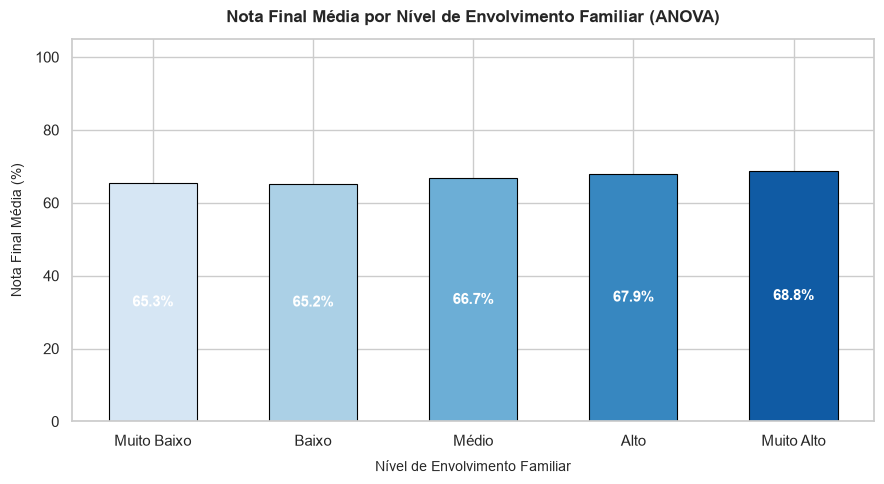

In [ ]:
# PASSO 5: VISUALIZAÇÃO GRÁFICA (BARRAS COM MÉDIAS INTERNAS)
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))

# Gráfico de barras com médias e paleta sequencial elegante
barras = ax.bar(
    tabela_descritiva.index.astype(str),
    tabela_descritiva["Média"].values,
    color=sns.color_palette("Blues_r", n_colors=len(ordem_categorias))[::-1],
    edgecolor="black",
    linewidth=0.8,
    width=0.55
)

# Adiciona o texto com a percentagem formatada no centro de cada barra
rotulos_medias = [f"{m:.1f}%" for m in tabela_descritiva["Média"].values]
ax.bar_label(
    barras,
    labels=rotulos_medias,
    label_type="center",
    color="white",
    fontsize=11,
    fontweight="bold"
)

# Configurações de títulos e eixos
ax.set_title("Nota Final Média por Nível de Envolvimento Familiar (ANOVA)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Nível de Envolvimento Familiar", fontsize=10, labelpad=8)
ax.set_ylabel("Nota Final Média (%)", fontsize=10, labelpad=8)
ax.set_ylim(0, 105)

# ----------------------------------------------------------
# PASSO 6: SALVAMENTO EM ALTA RESOLUÇÃO E EXIBIÇÃO
# ----------------------------------------------------------
#plt.tight_layout()
#nome_arquivo = "anova_envolvimento_familiar.png"
#fig.savefig(nome_arquivo, dpi=300, bbox_inches="tight")
#print(f"✅ Gráfico da ANOVA salvo com sucesso no arquivo: '{nome_arquivo}'")

# Exibe a figura no ecrã
plt.show()

## Grupo 2 Esturutura familiar

## Grupo 3 - Inclusão Tecnológica

## Grupo 4 - Situação escolar

# Etapa 2 - Análise de Clustering
O objetivo é construir uma análise de agrupamento (clustering) em K-Means com $k = 3$ focada em descobrir 3 perfis de alunos:
- Alto desempenho
- Desempenho na média
- Baixo desempenho

O modelo terá os seguintes parâmetros:
- Definição não arbitrária de faixas (thresholds): O algoritmo encontra onde estão as quebras naturais de notas na distribuição de final_grade_pct.
- Interpretabilidade e importância das variáveis: Determinar quais fatores da tua base (como tempo de estudo, envolvimento familiar parental_involvement_score, tamanho da família, etc.) mais contribuem para colocar um aluno em cada um desses grupos. Isso será feito com o treinamento de uma Decision Tree e um modelo de Feature Importance.

## Clusterização da Nota (K-Means k=3)
- O algoritmo agrupa as notas em 3 centróides.
- Ordenamos os clusters: Baixo (0) < Médio (1) < Alto (2).
- Identificação de thresholds de cada faixa.
- Criação da nova coluna 'perfil_desempenho' com os clusters correspondentes.

## Feature Importance e Decision Tree
- Treinamos o modelo preditor com Random Forest.
- Identificamos quais variáveis mais pesam na classificação.